In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Mall_Customers.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows:
0

Statistical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [3]:

# Select features for customer segmentation
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

print("Selected Features:")
print(X.head())

print("\nFeature Summary:")
print(X.describe())


Selected Features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Feature Summary:
       Annual Income (k$)  Spending Score (1-100)
count          200.000000              200.000000
mean            60.560000               50.200000
std             26.264721               25.823522
min             15.000000                1.000000
25%             41.500000               34.750000
50%             61.500000               50.000000
75%             78.000000               73.000000
max            137.000000               99.000000


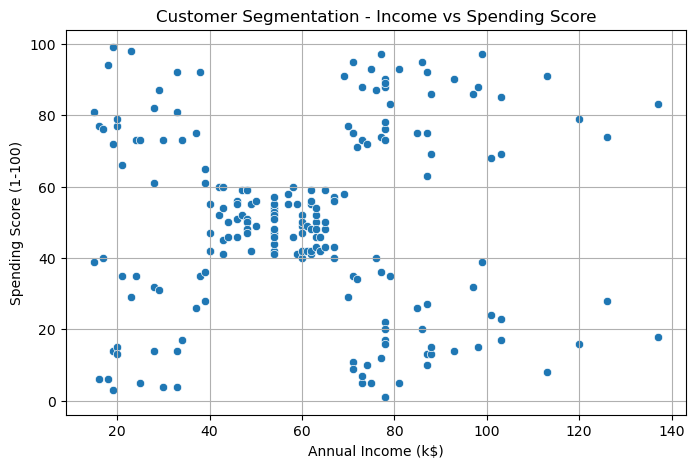

In [4]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)"
)

plt.title("Customer Segmentation - Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.grid(True)

plt.show()


In [5]:

from sklearn.cluster import KMeans

# Select income and spending score
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Create K-Means model with 5 clusters
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

# Train the model
df["Cluster"] = kmeans.fit_predict(X)

print("Customer Segmentation Completed!")
print("\nCluster-wise Customer Count:")
print(df["Cluster"].value_counts().sort_index())


Customer Segmentation Completed!

Cluster-wise Customer Count:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


c:\Users\rkamb\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


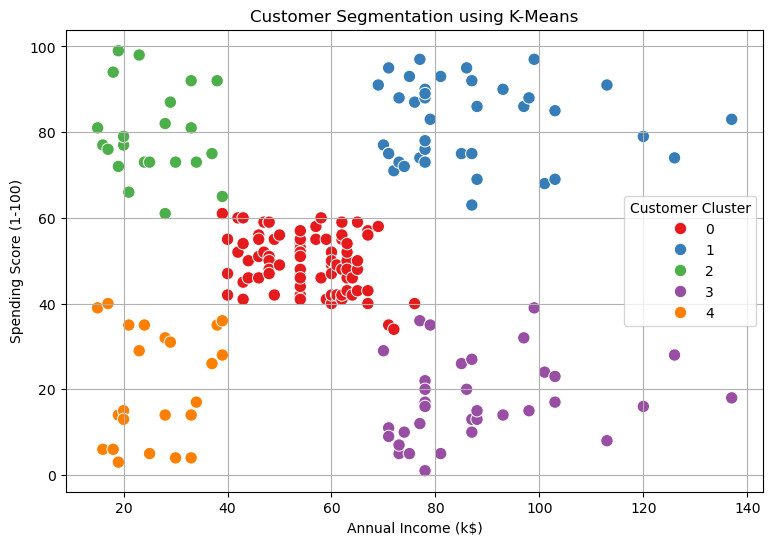

In [6]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set1",
    s=80
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Cluster")
plt.grid(True)

plt.show()


In [7]:

cluster_summary = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
).round(2)

print("Customer Cluster Summary:")
print(cluster_summary)


Customer Cluster Summary:
         Customer_Count  Average_Income  Average_Spending
Cluster                                                  
0                    81           55.30             49.52
1                    39           86.54             82.13
2                    22           25.73             79.36
3                    35           88.20             17.11
4                    23           26.30             20.91


In [8]:

print(cluster_summary.to_string())


         Customer_Count  Average_Income  Average_Spending
Cluster                                                  
0                    81           55.30             49.52
1                    39           86.54             82.13
2                    22           25.73             79.36
3                    35           88.20             17.11
4                    23           26.30             20.91


In [9]:

print(df[df["Cluster"] == 4][
    ["Annual Income (k$)", "Spending Score (1-100)"]
].mean())

print("\nCluster 4 Customer Count:")
print((df["Cluster"] == 4).sum())


Annual Income (k$)        26.304348
Spending Score (1-100)    20.913043
dtype: float64

Cluster 4 Customer Count:
23


## Customer Segmentation Findings

The K-Means clustering algorithm divided 200 customers into five groups based on annual income and spending score.

1. **Cluster 0 – Average Customers:** This is the largest group, with 81 customers. Their average income is $55.30k and average spending score is 49.52.
2. **Cluster 1 – High-Income, High-Spending Customers:** This group contains 39 customers. They have high average income and spending scores, making them a valuable target for loyalty rewards and premium offers.
3. **Cluster 2 – Low-Income, High-Spending Customers:** This group contains 22 customers. Discounts, affordable bundles, and promotional offers may help retain these customers.
4. **Cluster 3 – High-Income, Low-Spending Customers:** This group contains 35 customers. Personalized recommendations and exclusive offers may encourage more purchases.
5. **Cluster 4 – Low-Income, Low-Spending Customers:** This group contains 23 customers. Budget-friendly products and value deals may be suitable for this group.

## Marketing Recommendations

- Provide loyalty rewards and exclusive benefits to Cluster 1.
- Offer discounts and affordable product bundles to Cluster 2.
- Use personalized promotions to increase engagement in Cluster 3.
- Provide budget-friendly deals for Cluster 4.
- Use general promotional campaigns to maintain engagement with Cluster 0.

## Conclusion

Customer segmentation helps businesses understand different customer groups and plan targeted marketing strategies. K-Means clustering identified five groups based on annual income and spending score. These insights can support customer engagement, personalized promotions, and marketing decisions.